# 05 MACHINE LEARNING - TECHNIQUES - REVIEW EXERCISE - ML WORKFLOWS (SOLUTIONS)
This exercise will guide you through multiple ML workflows:
1. Linear & Polynomial Regression (Concrete dataset)
2. Classification with Decision Tree, Random Forest, GridSearchCV, and RandomizedSearchCV (Iris dataset)
3. K-Means Clustering on the Iris dataset

## 0. Setup
Import all necessary libraries for regression, classification, and clustering.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV, \
    RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, classification_report, \
    silhouette_score, root_mean_squared_error
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

RANDOM_STATE = 42

## 1. Concrete Dataset — Linear and Polynomial Regression
Load the concrete_data.csv dataset and perform a linear regression predicting concrete strength (`csMPa`) from the cement feature only. Then, extend this with polynomial regression (e.g., degree 2 or 3) to see if model performance improves. Evaluate both models with MAE, MSE, RMSE, and R².

In [28]:
df = pd.read_csv('../05a-ml-basics/data/Concrete_Data.csv')
df = df.rename(columns={'Cement (component 1)(kg in a m^3 mixture)': 'cement',
                        'Concrete compressive strength(MPa, megapascals) ': 'csMPa'})
X = df[['cement']]
y = df['csMPa']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
linreg = LinearRegression().fit(X_train, y_train)
y_pred = linreg.predict(X_test)
print('Linear Regression MAE:', mean_absolute_error(y_test, y_pred))
print('Linear Regression MSE:', mean_squared_error(y_test, y_pred))
print('Linear Regression RMSE:', root_mean_squared_error(y_test, y_pred))
print('Linear Regression R²:', r2_score(y_test, y_pred))
poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_poly, y, test_size=0.2, random_state=RANDOM_STATE)
polyreg = LinearRegression().fit(Xp_train, yp_train)
yp_pred = polyreg.predict(Xp_test)
print('Polynomial Regression MAE:', mean_absolute_error(yp_test, yp_pred))
print('Polynomial Regression MSE:', mean_squared_error(yp_test, yp_pred))
print('Polynomial Regression RMSE:', root_mean_squared_error(yp_test, yp_pred))
print('Polynomial Regression R²:', r2_score(yp_test, yp_pred))

Linear Regression MAE: 11.55561279863471
Linear Regression MSE: 192.78479855432548
Linear Regression RMSE: 13.884696559677689
Linear Regression R²: 0.25183513628298093
Polynomial Regression MAE: 11.585313394589495
Polynomial Regression MSE: 193.35856229354033
Polynomial Regression RMSE: 13.90534294052255
Polynomial Regression R²: 0.24960845724513925


## 2. Iris Dataset — Decision Tree and Random Forest
Train Decision Tree and Random Forest classifiers on the Iris dataset and show their mean accuracy based on 5-fold  cross-validation.

In [6]:
iris = load_iris()
X_i, y_i = iris.data, iris.target
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
rf = RandomForestClassifier(random_state=RANDOM_STATE)
for clf, name in [(dt, 'Decision Tree'), (rf, 'Random Forest')]:
    scores = cross_val_score(clf, X_i, y_i, cv=5, scoring='accuracy')
    print(name, 'mean accuracy:', scores.mean().round(3))

Decision Tree mean accuracy: 0.953
Random Forest mean accuracy: 0.967


### GridSearchCV for Decision Tree
Use GridSearchCV to find the best combination of hyperparameters such as `max_depth`, `min_samples_split`, and `criterion` for the decision tree classifier. Report the best parameters and score. Use 5 folds.

In [8]:
param_grid = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': [2, 4, 6, 8],
    'criterion': ['gini', 'entropy']
}
grid = GridSearchCV(dt, param_grid, cv=5, scoring='accuracy', n_jobs=-1  # Use all cores for parallel processing
                    )
grid.fit(X_i, y_i)
print('Best parameters (GridSearch):', grid.best_params_)
print('Best score:', np.round(grid.best_score_, 6))

Best parameters (GridSearch): {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best score: 0.973333


### RandomizedSearchCV for Decision Tree
Now try RandomizedSearchCV — it samples from distributions for parameters instead of testing every combination. This is useful when you have a large hyperparameter space. Use 5 folds.

In [9]:
rand = RandomizedSearchCV(dt, param_distributions=param_grid, cv=5, scoring='accuracy', random_state=RANDOM_STATE)
rand.fit(X_i, y_i)
print('Best parameters (RandomizedSearch):', rand.best_params_)
print('Best score:', np.round(rand.best_score_, 6))

Best parameters (RandomizedSearch): {'min_samples_split': 2, 'max_depth': 3, 'criterion': 'gini'}
Best score: 0.973333


### Evaluating the Decision Tree

Split the complete dataset into a train and test set (70/30). Train a Decision Tree Classifier using the best parameters found. Show the confusion matrix and classification report for the test set.

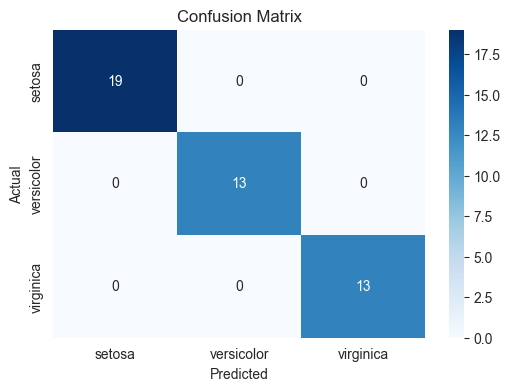


Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [32]:
best_params = grid.best_params_  # Get best params from GridSearch

X_train, X_test, y_train, y_test = train_test_split(X_i, y_i, test_size=0.3, random_state=42)

# Train Decision Tree
dt_best = DecisionTreeClassifier(**best_params, random_state=RANDOM_STATE)
dt_best.fit(X_train, y_train)

# Predict
y_pred = dt_best.predict(X_test)

# Show confusion matrix and classification report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

## 3. Iris Dataset — K-Means Clustering
Perform unsupervised clustering on the Iris dataset. Use the numeric features, standardize them, and try k values from 2 to 10. Plot the silhouette scores to determine a good number of clusters.

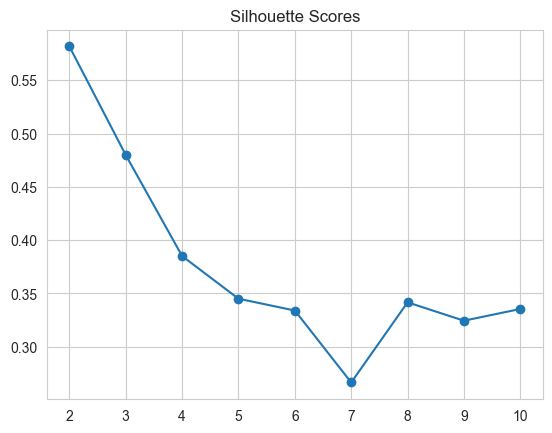

In [33]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_i)
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))
plt.plot(range(2, 11), sil_scores, marker='o')
plt.title('Silhouette Scores')
plt.show()

// todo explanation
## 📈 Silhouette Score Overview
- Silhouette score measures how well each data point fits within its assigned cluster compared to other clusters.
- Values range from −1 to +1:
- +1 → well-clustered
- 0 → overlapping clusters
- −1 → misclassifie



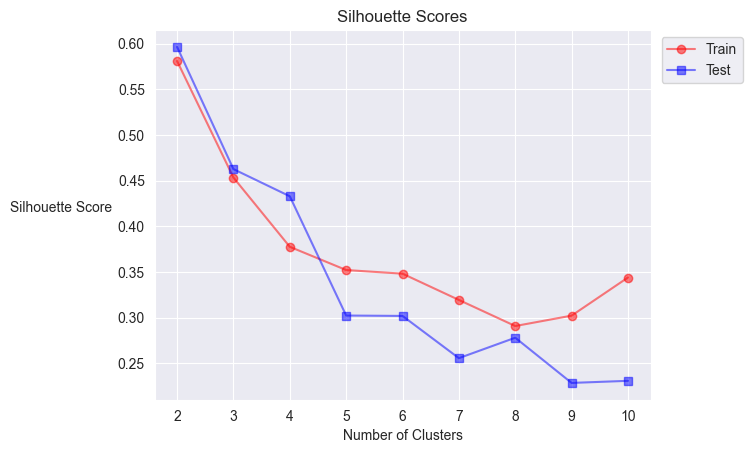

In [4]:
### extra me
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(X_i, y_i, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
sil_scores_train = []
sil_scores_test = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    labels_train = km.fit_predict(X_train_scaled)
    sil_scores_train.append(silhouette_score(X_train_scaled, labels_train))
    labels_test = km.predict(X_test_scaled)
    # This line is problematic because KMeans is unsupervised and does not generalize to new data like supervised models. The .predict() method assigns clusters based on proximity to centroids, but it’s not meaningful for evaluating silhouette score on unseen data unless the clusters are stable and well-separated.
    sil_scores_test.append(silhouette_score(X_test_scaled, labels_test))
plt.plot(range(2, 11), sil_scores_train, marker='o', label='Train',alpha=0.5,color='red')
plt.plot(range(2, 11), sil_scores_test, marker='s', label='Test',alpha=0.5,color='blue')
plt.legend(
    loc='upper right',
    bbox_to_anchor=(1.2, 1)
)
plt.xlabel('Number of Clusters')
plt.ylabel(
    'Silhouette Score',
    rotation=0,
    horizontalalignment='right'
)
plt.title('Silhouette Scores')
plt.show()